# AI & ML in Data-Centric Engineering Workshop

This workbook is the worked solution. It keeps the same structure as the participant notebook so you can compare the reasoning step by step.

The telemetry data is generated by the hidden emulator and intentionally shaped so the engineering ideas are visible: raw samples are noisy, pressure drifts, and the target depends on short history rather than a single snapshot.

Before you start, make sure `pump_telemetry.csv` exists in the workshop folder.

## Notebook Setup

These helper definitions keep the notebook readable. The point is to centralize the small pieces that will be reused later: loading the CSV safely, smoothing vibration, extracting rolling physical features, and enforcing simple safety bounds.

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.signal import savgol_filter
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (11, 6),
        "figure.dpi": 120,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.25,
        "legend.frameon": False,
        "font.size": 10,
    }
)

csv_candidates = [
    Path("pump_telemetry.csv"),
    Path("..").resolve() / "pump_telemetry.csv",
    Path.cwd() / "pump_telemetry.csv",
]
for candidate in csv_candidates:
    if candidate.exists():
        csv_path = candidate
        break
else:
    raise FileNotFoundError("Could not find pump_telemetry.csv in the expected locations.")

telemetry_df = pd.read_csv(csv_path, parse_dates=["timestamp"])


def rolling_rms(signal: np.ndarray, window: int = 61) -> np.ndarray:
    series = pd.Series(signal, dtype="float64")
    return (
        series.rolling(window=window, min_periods=1, center=True)
        .apply(lambda values: float(np.sqrt(np.mean(np.square(values)))), raw=True)
        .bfill()
        .ffill()
        .to_numpy()
    )


def rolling_trend(signal: np.ndarray, window: int = 31) -> np.ndarray:
    values = np.asarray(signal, dtype=float)
    half_window = window // 2
    trend_values = []

    for index in range(values.shape[0]):
        start = max(0, index - half_window)
        stop = min(values.shape[0], index + half_window + 1)
        window_values = values[start:stop]
        if window_values.size < 2:
            trend_values.append(np.nan)
        else:
            trend_values.append((window_values[-1] - window_values[0]) / max(1, window_values.size - 1))

    return pd.Series(trend_values).bfill().ffill().to_numpy()


def enforce_physical_limits(predictions: np.ndarray, inputs: pd.DataFrame) -> np.ndarray:
    bounded = np.clip(np.asarray(predictions, dtype=float), 0.0, 1.0)
    cavitation_mask = inputs["pressure_reserve"].to_numpy() < -7.5
    return np.where(cavitation_mask, np.minimum(bounded, 0.2), bounded)


## Part 1: The Dirty Reality

Physical telemetry is rarely clean. Sparse dropouts are already present in the emulator output, so they need to be forward-filled because the machine state does not genuinely jump to missing, high-frequency electrical noise needs smoothing without erasing real mechanical peaks, and pressure sensors need deterministic drift removal when the error grows slowly over time.

Injected dropout rows: 48
                      timestamp  raw_vibration  cleaned_vibration  \
0 2026-01-01 00:00:00.000000000      -0.114537          -0.080171   
1 2026-01-01 00:04:59.999999998       0.164215          -0.074554   
2 2026-01-01 00:10:00.000000001      -0.519329          -0.067156   
3 2026-01-01 00:15:00.000000000       0.388936          -0.057976   
4 2026-01-01 00:19:59.999999998      -0.547526          -0.047015   

   drifted_pressure  calibrated_pressure  
0        118.543247           118.543247  
1        119.417195           119.421362  
2        119.587860           119.596193  
3        120.183256           120.195756  
4        119.587906           119.604572  


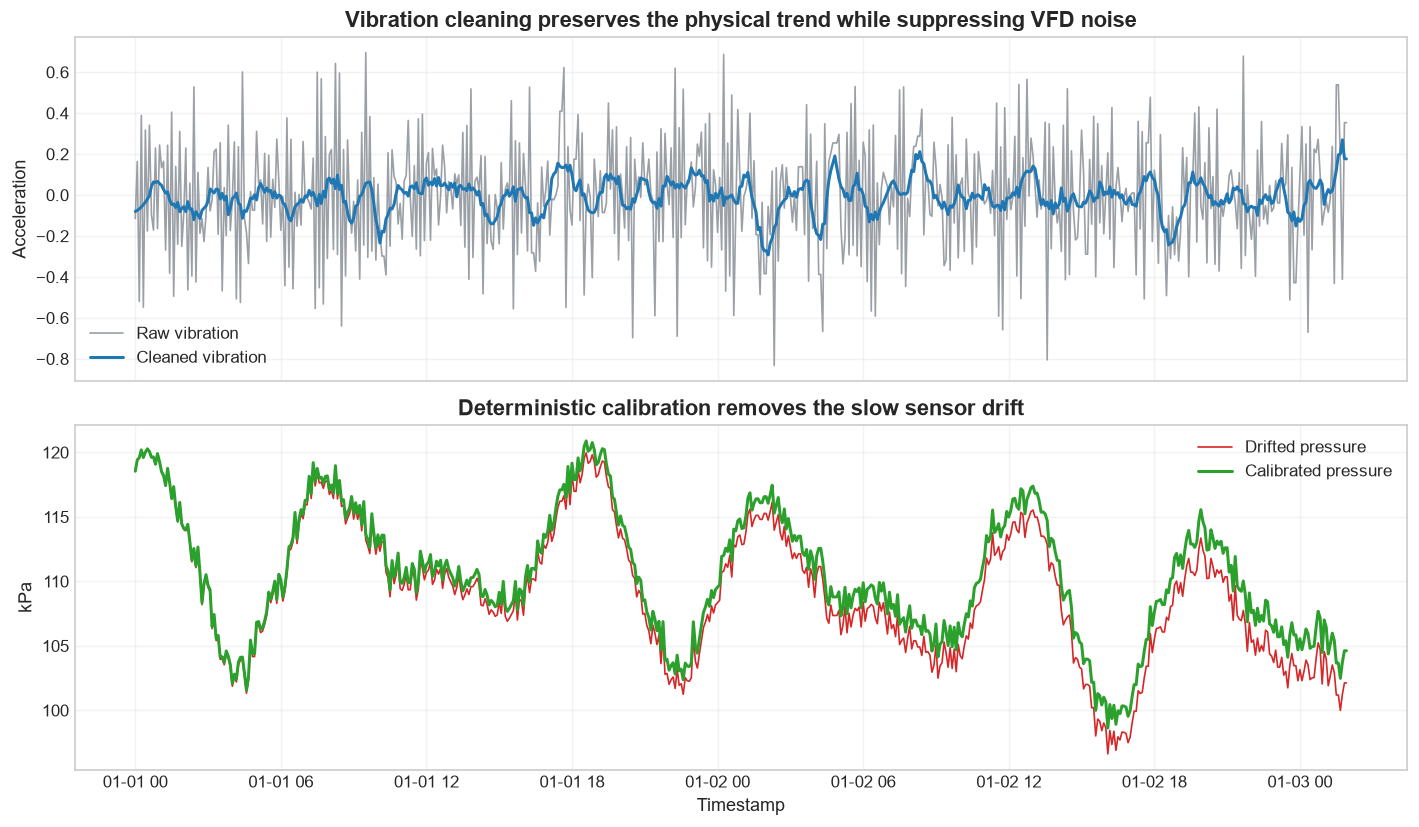

In [15]:
working_df = telemetry_df.copy()

dropout_count = int(working_df[["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]].isna().any(axis=1).sum())

working_df[["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]] = working_df[
    ["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]
].ffill()
working_df["cleaned_vibration"] = savgol_filter(working_df["raw_vibration"].to_numpy(), window_length=15, polyorder=2)

calibrated_pressure = []
for hour, pressure in zip(working_df["time_hours"].to_numpy(), working_df["drifted_pressure"].to_numpy()):
    calibrated_pressure.append(pressure + 0.05 * hour)
working_df["calibrated_pressure"] = calibrated_pressure

print(f"Injected dropout rows: {dropout_count}")
print(
    working_df[["timestamp", "raw_vibration", "cleaned_vibration", "drifted_pressure", "calibrated_pressure"]].head()
)

preview = working_df.iloc[:600].copy()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(preview["timestamp"], preview["raw_vibration"], color="#9aa0a6", linewidth=1, label="Raw vibration")
axes[0].plot(preview["timestamp"], preview["cleaned_vibration"], color="#1f77b4", linewidth=1.8, label="Cleaned vibration")
axes[0].set_title("Vibration cleaning preserves the physical trend while suppressing VFD noise")
axes[0].set_ylabel("Acceleration")
axes[0].legend()

axes[1].plot(preview["timestamp"], preview["drifted_pressure"], color="#d62728", linewidth=1, label="Drifted pressure")
axes[1].plot(preview["timestamp"], preview["calibrated_pressure"], color="#2ca02c", linewidth=1.8, label="Calibrated pressure")
axes[1].set_title("Deterministic calibration removes the slow sensor drift")
axes[1].set_ylabel("kPa")
axes[1].set_xlabel("Timestamp")
axes[1].legend()
plt.tight_layout()
plt.show()

## Part 2: Feature Engineering

A naive model sees only individual samples. A data-centric model sees the physics hidden inside a short history window. Here we compare a raw-feature baseline against engineered vibration RMS, vibration trend, and pressure reserve features.

Naive raw-feature R^2: 0.220
Engineered physics-feature R^2: 0.790
Improvement: 0.570


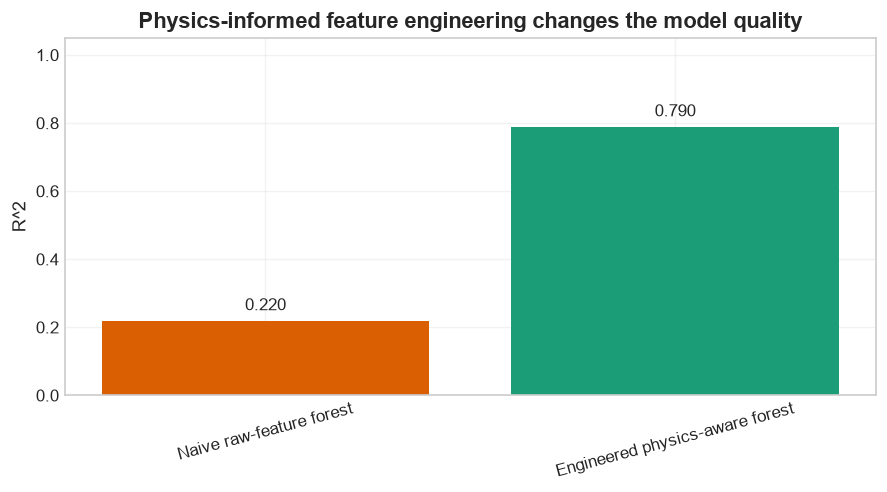

In [16]:
raw_features = ["raw_vibration", "drifted_pressure", "motor_temp"]
engineered_features = ["vibration_rms", "vibration_trend", "pressure_reserve", "motor_temp"]

vibration_rms = rolling_rms(working_df["cleaned_vibration"].to_numpy(), window=61)
vibration_trend = rolling_trend(working_df["cleaned_vibration"].to_numpy(), window=31)
pressure_reserve_feature = (
    working_df["calibrated_pressure"].to_numpy()
    - pd.Series(working_df["calibrated_pressure"]).rolling(window=91, min_periods=1, center=True).mean().bfill().ffill().to_numpy()
 )

feature_array = np.column_stack(
    [
        working_df["raw_vibration"].to_numpy(),
        working_df["drifted_pressure"].to_numpy(),
        working_df["motor_temp"].to_numpy(),
        vibration_rms,
        vibration_trend,
        pressure_reserve_feature,
        working_df["pump_efficiency"].to_numpy(),
    ]
)

feature_df = pd.DataFrame(
    feature_array,
    columns=[
        "raw_vibration",
        "drifted_pressure",
        "motor_temp",
        "vibration_rms",
        "vibration_trend",
        "pressure_reserve",
        "pump_efficiency",
    ],
)

train_df, test_df = train_test_split(feature_df, test_size=0.3, random_state=42, shuffle=True)

baseline_model = RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1)
baseline_model.fit(train_df[raw_features], train_df["pump_efficiency"])
baseline_predictions = baseline_model.predict(test_df[raw_features])
baseline_r2 = r2_score(test_df["pump_efficiency"], baseline_predictions)

engineered_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
engineered_model.fit(train_df[engineered_features], train_df["pump_efficiency"])
engineered_predictions = engineered_model.predict(test_df[engineered_features])
engineered_r2 = r2_score(test_df["pump_efficiency"], engineered_predictions)

print(f"Naive raw-feature R^2: {baseline_r2:.3f}")
print(f"Engineered physics-feature R^2: {engineered_r2:.3f}")
print(f"Improvement: {engineered_r2 - baseline_r2:.3f}")

comparison = pd.DataFrame(
    {
        "model": ["Naive raw-feature forest", "Engineered physics-aware forest"],
        "r2": [baseline_r2, engineered_r2],
    }
)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(comparison["model"], comparison["r2"], color=["#d95f02", "#1b9e77"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("R^2")
ax.set_title("Physics-informed feature engineering changes the model quality")
ax.tick_params(axis="x", rotation=15)
for idx, value in enumerate(comparison["r2"]):
    ax.text(idx, value + 0.02, f"{value:.3f}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()


## Part 3: Boundary Concepts and Uncertainty

When the pump leaves its familiar operating envelope, confidence matters as much as the point prediction. A tree ensemble is useful here because the spread across trees grows naturally when the input moves into a region the model has not really seen.

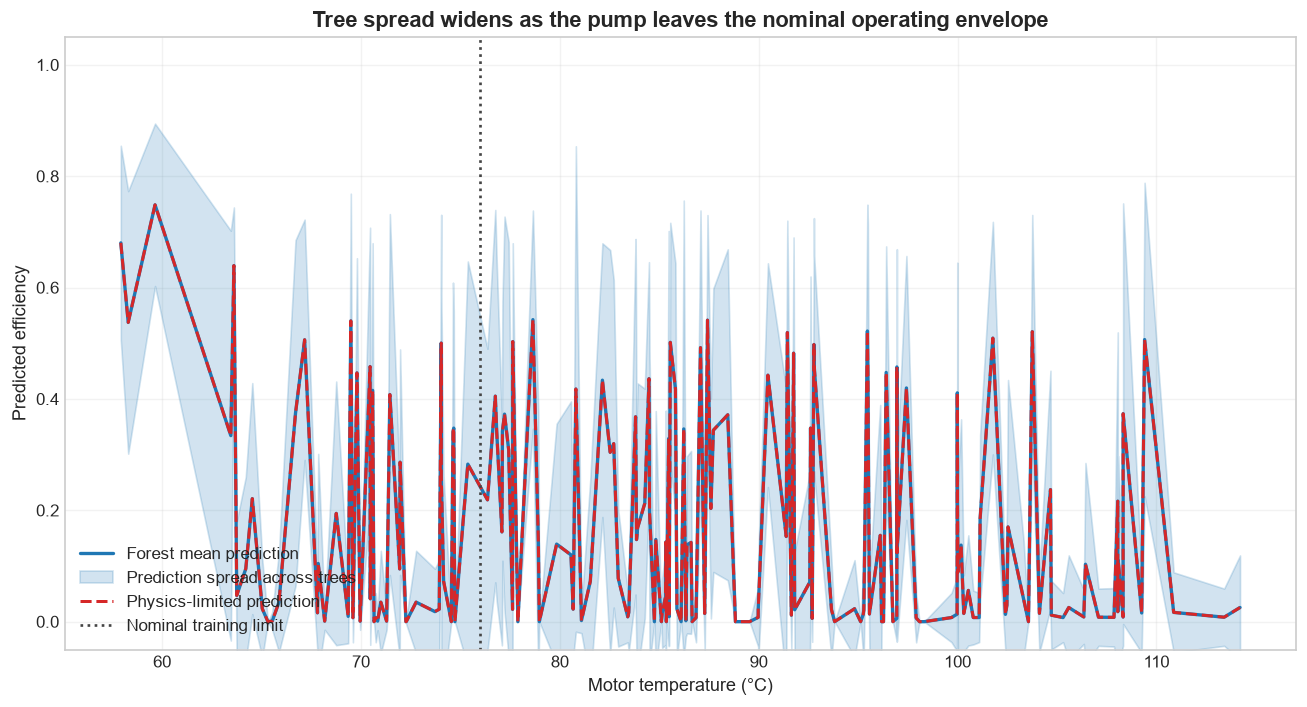

OOD mean prediction range: 0.000 to 0.749
OOD uncertainty range: 0.000 to 0.291
Physics-limited tail values: [0.01564007 0.50659233 0.01667122 0.00800803 0.02545766]


In [21]:
nominal_mask = (train_df["motor_temp"] < 68.0) & (train_df["pressure_reserve"] > -4.0)
nominal_pool = train_df.loc[nominal_mask, engineered_features + ["pump_efficiency"]].dropna().copy()
nominal_sample = nominal_pool.sample(n=min(650, len(nominal_pool)), random_state=42).sort_index()

X_nominal = nominal_sample[engineered_features].copy()
y_nominal = nominal_sample["pump_efficiency"].to_numpy()

gpr_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
gpr_model.fit(X_nominal.to_numpy(), y_nominal)

ood_slice = test_df.iloc[:180].copy()
tail_mask = np.zeros(len(ood_slice), dtype=bool)
tail_mask[-18:] = True
ood_slice = ood_slice.assign(
    motor_temp=ood_slice["motor_temp"].astype(float).to_numpy() + np.linspace(0.0, 45.0, len(ood_slice)),
    pressure_reserve=np.where(tail_mask, -8.0, ood_slice["pressure_reserve"].to_numpy()),
)

ood_matrix = ood_slice[engineered_features].to_numpy()
ood_trees = np.stack([tree.predict(ood_matrix) for tree in gpr_model.estimators_], axis=0)
ood_mean = ood_trees.mean(axis=0)
ood_std = ood_trees.std(axis=0)
validated_mean = enforce_physical_limits(ood_mean, ood_slice)

x_axis = ood_slice["motor_temp"].to_numpy()
order = np.argsort(x_axis)
x_sorted = x_axis[order]
mean_sorted = ood_mean[order]
std_sorted = ood_std[order]
validated_sorted = validated_mean[order]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(x_sorted, mean_sorted, color="#1f77b4", linewidth=2, label="Forest mean prediction")
ax.fill_between(
    x_sorted,
    mean_sorted - 1.5 * std_sorted,
    mean_sorted + 1.5 * std_sorted,
    color="#1f77b4",
    alpha=0.2,
    label="Prediction spread across trees",
)
ax.plot(x_sorted, validated_sorted, color="#d62728", linewidth=1.8, linestyle="--", label="Physics-limited prediction")
nominal_max = train_df["motor_temp"].max()
ax.axvline(nominal_max, color="#444444", linestyle=":", linewidth=1.6, label="Nominal training limit")
ax.set_xlabel("Motor temperature (°C)")
ax.set_ylabel("Predicted efficiency")
ax.set_title("Tree spread widens as the pump leaves the nominal operating envelope")
ax.set_ylim(-0.05, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

print(f"OOD mean prediction range: {ood_mean.min():.3f} to {ood_mean.max():.3f}")
print(f"OOD uncertainty range: {ood_std.min():.3f} to {ood_std.max():.3f}")
print(f"Physics-limited tail values: {validated_sorted[-5:]}")


## Part 4: Ethics and Forensic Audit

Explainability is not decorative. In a safety-critical asset, feature attributions are part of the audit trail. SHAP helps show which sensor channel is responsible for a shutdown-level prediction instead of leaving the explanation buried inside a black box.

Mean absolute SHAP importance:
pressure_reserve    0.178549
motor_temp          0.049311
vibration_trend     0.008019
vibration_rms       0.007745
dtype: float64
Dominant sensor channel: pressure_reserve


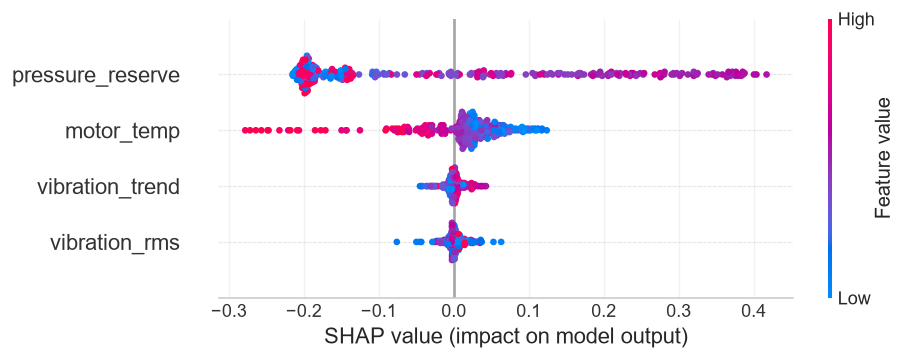

Most anomalous telemetry frame index within SHAP sample: 2


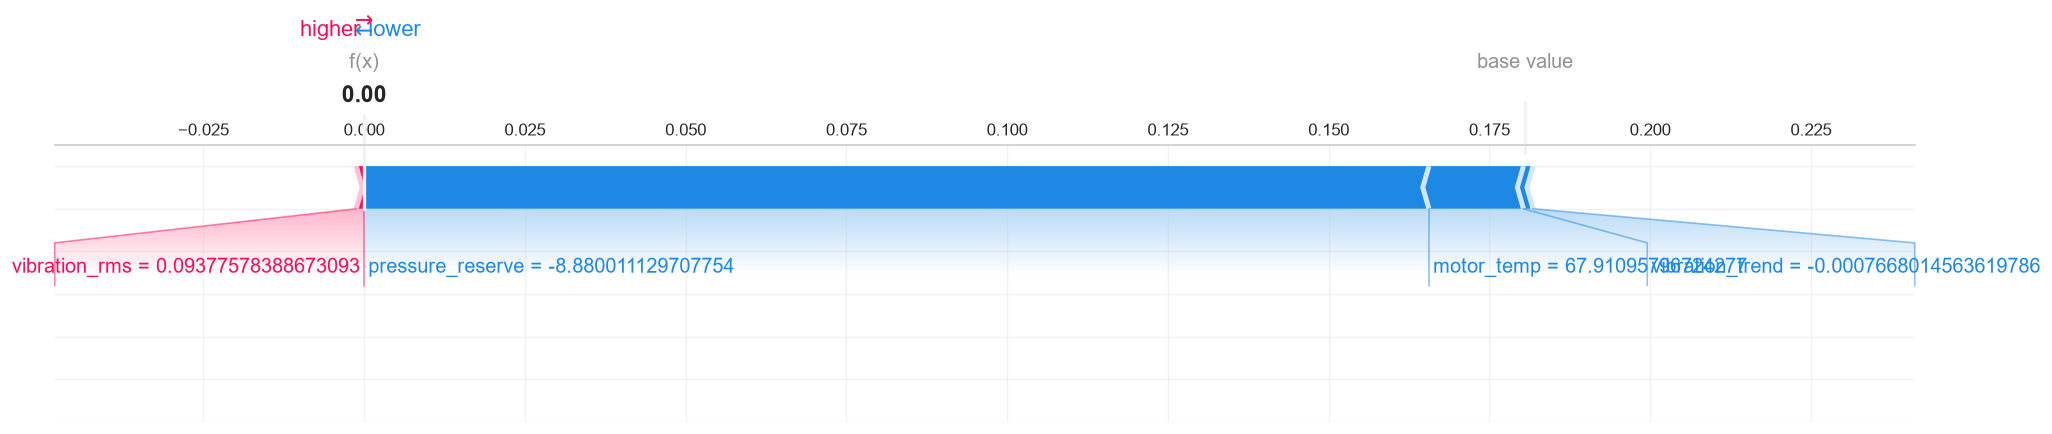

In [18]:
shap.initjs()
shap_sample = test_df.sample(n=min(300, len(test_df)), random_state=42).copy()
X_shap = shap_sample[engineered_features]
shap_explainer = shap.TreeExplainer(engineered_model)
shap_values = shap_explainer.shap_values(X_shap)

feature_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=engineered_features).sort_values(ascending=False)
dominant_feature = feature_importance.index[0]
print("Mean absolute SHAP importance:")
print(feature_importance)
print(f"Dominant sensor channel: {dominant_feature}")

shap.summary_plot(shap_values, X_shap, show=True)

top_row = int(np.argmin(engineered_model.predict(X_shap)))
expected_value = float(np.asarray(shap_explainer.expected_value).squeeze())
print(f"Most anomalous telemetry frame index within SHAP sample: {top_row}")
shap.force_plot(
    expected_value,
    shap_values[top_row],
    X_shap.iloc[top_row],
    matplotlib=True,
    show=True,
)


## Wrap-Up

If the notebook is working, the raw features should look weak, the engineered features should recover the physical signal, the uncertainty band should widen in the extrapolation zone, and SHAP should point to a specific sensor channel rather than a vague story.